# Разделение данных для обучения и тестирования, перекрестная валидация и линейная регрессия

Выполнил: Dimitriu Eduard, IASD 2602 Ru

Отдельного файла с заданиями к Lab 3 не было, поэтому вопросы взял из ноутбука к лабе, а решения писал сам.

# Цели обучения

- Объяснить разницу между переобучением и недообучением модели
- Описать компромисс между систематической ошибкой и дисперсией
- Определить оптимальное разделение наборов данных для обучения и тестирования, провести перекрестную валидацию и проанализировать взаимосвязь между сложностью модели и погрешностью
- Применить модель линейной регрессии для обучения с учителем
- Применить расширение Intel® для Scikit-learn*, чтобы использовать вычислительные возможности аппаратного обеспечения


## Введение

Мы будем работать с набором данных, основанным на [ценах на жилье в Эймсе, штат Айова](https://www.kaggle.com/c/house-prices-advanced-regression-techniques). Он был составлен для учебных целей в качестве обновленной и расширенной альтернативы хорошо известному набору данных «Boston Housing». В этой версии набора данных для удобства были восстановлены некоторые пропущенные значения.

Количество признаков довольно велико, поэтому они описаны в таблице ниже.

### Прогнозируемая переменная

* SalePrice: цена продажи недвижимости в долларах.


### Features

<table>
  <tbody>    
    <tr valign="top">
      <td valign="top">
        <ul>
          <li>MoSold: Month Sold</li>
          <li>YrSold: Year Sold</li><br>
          
          <li>SaleType: Type of sale</li>
          <li>SaleCondition: Condition of sale</li><br>

          <li>MSSubClass: The building class</li>
          <li>MSZoning: The general zoning classification</li><br>

          <li>Neighborhood: Physical locations within Ames city limits</li>
          <li>Street: Type of road access</li>
          <li>Alley: Type of alley access</li><br>

          <li>LotArea: Lot size in square feet</li>
          <li>LotConfig: Lot configuration</li>
          <li>LotFrontage: Linear feet of street connected to property</li>
          <li>LotShape: General shape of property</li><br>

          <li>LandSlope: Slope of property</li>
          <li>LandContour: Flatness of the property</li><br>

          <li>YearBuilt: Original construction date</li>
          <li>YearRemodAdd: Remodel date</li>
          <li>OverallQual: Overall material and finish quality</li>
          <li>OverallCond: Overall condition rating</li><br>

          <li>Utilities: Type of utilities available</li>
          <li>Foundation: Type of foundation</li>
          <li>Functional: Home functionality rating</li><br>

          <li>BldgType: Type of dwelling</li>
          <li>HouseStyle: Style of dwelling</li><br>
          
          <li>1stFlrSF: First Floor square feet</li>
          <li>2ndFlrSF: Second floor square feet</li>
          <li>LowQualFinSF: Low quality finished square feet (all floors)</li>
          <li>GrLivArea: Above grade (ground) living area square feet</li>
          <li>TotRmsAbvGrd: Total rooms above grade (does not include bathrooms)</li><br>

          <li>Condition1: Proximity to main road or railroad</li>
          <li>Condition2: Proximity to main road or railroad (if a second is present)</li><br>
          
          <li>RoofStyle: Type of roof</li>
          <li>RoofMatl: Roof material</li><br>

          <li>ExterQual: Exterior material quality</li>
          <li>ExterCond: Present condition of the material on the exterior</li>
          <li>Exterior1st: Exterior covering on house</li>
          <li>Exterior2nd: Exterior covering on house (if more than one material)</li><br><br>
          
        </ul>
      </td>
      
      <td valign="top">
        <ul>
          <li>MasVnrType: Masonry veneer type</li>
          <li>MasVnrArea: Masonry veneer area in square feet</li><br>
          
          <li>WoodDeckSF: Wood deck area in square feet</li>
          <li>OpenPorchSF: Open porch area in square feet</li>
          <li>EnclosedPorch: Enclosed porch area in square feet</li>
          <li>3SsnPorch: Three season porch area in square feet</li>
          <li>ScreenPorch: Screen porch area in square feet</li><br>

          <li>PoolArea: Pool area in square feet</li>
          <li>PoolQC: Pool quality</li>
          <li>Fence: Fence quality</li>
          <li>PavedDrive: Paved driveway</li><br>

          <li>GarageType: Garage location</li>
          <li>GarageYrBlt: Year garage was built</li>
          <li>GarageFinish: Interior finish of the garage</li>
          <li>GarageCars: Size of garage in car capacity</li>
          <li>GarageArea: Size of garage in square feet</li>
          <li>GarageQual: Garage quality</li>
          <li>GarageCond: Garage condition</li><br>

          <li>Heating: Type of heating</li>
          <li>HeatingQC: Heating quality and condition</li>
          <li>CentralAir: Central air conditioning</li>
          <li>Electrical: Electrical system</li><br>
          
          <li>FullBath: Full bathrooms above grade</li>
          <li>HalfBath: Half baths above grade</li><br>
          
          <li>BedroomAbvGr: Number of bedrooms above basement level</li><br>
          
          <li>KitchenAbvGr: Number of kitchens</li>
          <li>KitchenQual: Kitchen quality</li><br>
          
          <li>Fireplaces: Number of fireplaces</li>
          <li>FireplaceQu: Fireplace quality</li><br>
          
          <li>MiscFeature: Miscellaneous feature not covered in other categories</li>
          <li>MiscVal: Value of miscellaneous feature</li><br>
          
          <li>BsmtQual: Height of the basement</li>
          <li>BsmtCond: General condition of the basement</li>
          <li>BsmtExposure: Walkout or garden level basement walls</li>
          <li>BsmtFinType1: Quality of basement finished area</li>
          <li>BsmtFinSF1: Type 1 finished square feet</li>
          <li>BsmtFinType2: Quality of second finished area (if present)</li>
          <li>BsmtFinSF2: Type 2 finished square feet</li>
          <li>BsmtUnfSF: Unfinished square feet of basement area</li>
          <li>BsmtFullBath: Basement full bathrooms</li>
          <li>BsmtHalfBath: Basement half bathrooms</li>
          <li>TotalBsmtSF: Total square feet of basement area</li>
        </ul>
      </td>
    </tr>
    
  </tbody>
</table>


In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, MaxAbsScaler
from sklearn.model_selection import train_test_split, KFold, cross_val_score, learning_curve
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

try:  # Intel Extension ускоряет sklearn, если установлен
    from sklearnex import patch_sklearn
    patch_sklearn()
except ImportError:
    print("scikit-learn-intelex не установлен, используется стандартный scikit-learn")

RANDOM_STATE = 42
pd.options.mode.chained_assignment = None

scikit-learn-intelex не установлен, используется стандартный scikit-learn


## Вопрос 1

* Импортируйте данные с помощью Pandas и проанализируйте их структуру. В наборе данных 79 столбцов с признаками, а также предиктор — цена продажи (`SalePrice`).
* В наборе данных присутствуют три различных типа: целые числа (`int64`), числа с плавающей запятой (`float64`) и строки (`object`, категориальные значения). Определите, сколько значений каждого типа данных присутствует в наборе.

In [2]:
FILE = "Ames_Housing_Sales.csv"
path = FILE if os.path.exists(FILE) else os.path.join("..", "materials", FILE)
data = pd.read_csv(path)
print("Размерность:", data.shape)
print("Признаков (без SalePrice):", data.shape[1] - 1)
data.dtypes.astype(str).replace({"str": "object"}).value_counts()

Размерность: (1379, 80)
Признаков (без SalePrice): 79


object     43
float64    21
int64      16
Name: count, dtype: int64

In [3]:
data[["SalePrice", "GrLivArea", "OverallQual", "YearBuilt", "Neighborhood"]].head()

,SalePrice,GrLivArea,OverallQual,YearBuilt,Neighborhood
0,208500.0,1710.0,7,2003,CollgCr
1,181500.0,1262.0,6,1976,Veenker
2,223500.0,1786.0,7,2001,CollgCr
3,140000.0,1717.0,7,1915,Crawfor
4,250000.0,2198.0,8,2000,NoRidge


В данных 1379 домов и 80 столбцов: 79 признаков и `SalePrice`. Строковых (категориальных) признаков 43, `float64` 21 и `int64` 16. Часть целых величин, например площади, сохранена как float.

## Вопрос 2

Как обсуждалось на лекции, одной из основных сложностей, особенно при работе с данными, содержащими большое количество столбцов, является обеспечение правильного кодирования каждого столбца.

Это особенно актуально в случае столбцов данных, содержащих упорядоченные категориальные переменные (порядковые) по сравнению с неупорядоченными категориальными переменными. Неупорядоченные категориальные переменные следует кодировать методом «one-hot», однако это может значительно увеличить количество признаков и привести к появлению признаков, сильно коррелирующих друг с другом.

Определите, какое общее количество признаков будет присутствовать по сравнению с тем, что существует в настоящее время, если все строковые (объектные) признаки будут закодированы по методу «one-hot». Напомним, что общее количество столбцов, закодированных по методу «one-hot», равно `n-1`, где `n` — количество категорий.

In [4]:
categorical_cols = data.select_dtypes(include=["object", "string"]).columns
n_unique = data[categorical_cols].nunique().sort_values(ascending=False)
print("Строковых признаков:", len(categorical_cols))
print(n_unique.head(10))

# one-hot для признака с n категориями даёт n-1 новых столбцов (исходный удаляется); с 1 категорией не нужен
extra = (n_unique[n_unique > 1] - 1).sum()
print("\nДополнительных столбцов после one-hot:", extra)
print("Признаков было:", data.shape[1] - 1, "-> станет:", data.shape[1] - 1 + extra)

Строковых признаков: 43
Neighborhood    25
Exterior2nd     16
Exterior1st     14
SaleType         9
Condition1       9
RoofMatl         8
HouseStyle       8
Condition2       8
Functional       7
GarageType       6
dtype: int64

Дополнительных столбцов после one-hot: 204
Признаков было: 79 -> станет: 283


Если считать только заполненные категории, one-hot добавит 204 столбца, и признаков станет 283 вместо 79, примерно в 3,6 раза больше. Ниже я кодирую пропуски (NaN) как отдельную категорию, поэтому там выходит 215. Для 1379 домов это очень много признаков, линейная регрессия на них легко переобучится.

## Вопрос 3

Давайте создадим новый набор данных, в котором все вышеперечисленные категориальные признаки будут закодированы по методу «one-hot». Мы можем провести обучение на этих данных и посмотреть, как это повлияет на результаты.

* Используем метод `.copy()` датафрейма, чтобы создать полностью отдельную копию датафрейма для кодирования по принципу «one-hot».
* В этом новом датафрейме закодируем по принципу «one-hot» каждый из соответствующих столбцов и добавим его обратно в датафрейм. Обязательно удалите исходный столбец.
* Для данных, которые не кодируются по принципу «one-hot», удалите столбцы, представляющие собой строковые категориальные переменные.

На первом этапе, при числовом кодировании строковых категориальных переменных, можно использовать либо `LabelEncoder`, либо `DictVectorizer` из Scikit-learn. Однако первый вариант, вероятно, проще, поскольку не требует указания числового значения для каждой категории, а мы в любом случае будем применять кодирование «one-hot» ко всем числовым значениям. (Можете ли вы придумать ситуацию, в которой предпочтительнее использовать `DictVectorizer`?)

In [5]:
data_ohc = data.copy()
for col in n_unique.index:
    enc = OneHotEncoder(sparse_output=False, drop="first")
    encoded = enc.fit_transform(data_ohc[[col]].astype(str))
    names = [f"{col}_{c}" for c in enc.categories_[0][1:]]
    data_ohc = pd.concat([data_ohc.drop(columns=col),
                          pd.DataFrame(encoded, index=data_ohc.index, columns=names)], axis=1)

# Набор без кодирования: строковые столбцы просто удаляем
data_num = data.drop(columns=categorical_cols)
print("Добавлено one-hot столбцов:", data_ohc.shape[1] - data_num.shape[1],
      "(пропуски NaN закодированы как отдельная категория)")
print("Без кодирования:", data_num.shape, " One-hot:", data_ohc.shape)

Добавлено one-hot столбцов: 215 (пропуски NaN закодированы как отдельная категория)
Без кодирования: (1379, 37)  One-hot: (1379, 252)


Я взял `OneHotEncoder(drop="first")`. Он сразу кодирует строки, `LabelEncoder` перед ним не нужен, и выкидывает одну категорию у каждого признака. Иначе столбцы одного признака в сумме всегда дают 1, и для линейной регрессии это полная мультиколлинеарность (dummy trap). Поэтому на признак получается n − 1 столбец, как и считали в вопросе 2.

## Вопрос 4

* Разделите оба набора данных на обучающую и тестовую части. Чтобы обеспечить одинаковое разделение данных, используйте одинаковый параметр `random_state` при разделении каждого из наборов.
* Для каждого набора данных постройте базовую линейную регрессионную модель на обучающих данных.
* Рассчитайте среднеквадратичную ошибку для соответствующих моделей как на обучающем, так и на тестовом наборах данных. Какая модель дает меньшую ошибку на тестовых данных и почему?

In [6]:
y_col = "SalePrice"

X = data_num.drop(columns=y_col); y = data_num[y_col]
X_ohc = data_ohc.drop(columns=y_col); y_ohc = data_ohc[y_col]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE)
X_train_ohc, X_test_ohc, y_train_ohc, y_test_ohc = train_test_split(X_ohc, y_ohc, test_size=0.3, random_state=RANDOM_STATE)
print("Одинаковое разбиение:", (X_train.index == X_train_ohc.index).all())

rows = {}
for name, (Xtr, ytr, Xte, yte) in {"без кодирования": (X_train, y_train, X_test, y_test),
                                   "one-hot": (X_train_ohc, y_train_ohc, X_test_ohc, y_test_ohc)}.items():
    lr = LinearRegression().fit(Xtr, ytr)
    rows[name] = {"MSE train": mean_squared_error(ytr, lr.predict(Xtr)),
                  "MSE test": mean_squared_error(yte, lr.predict(Xte)),
                  "R2 test": r2_score(yte, lr.predict(Xte))}
errors = pd.DataFrame(rows).T
errors.style.format({"MSE train": "{:.3e}", "MSE test": "{:.3e}", "R2 test": "{:.4f}"})

Одинаковое разбиение: True


,MSE train,MSE test,R2 test
без кодирования,1.132e+09,1.372e+09,0.7727
one-hot,3.432e+08,2.698e+09,0.5530


С one-hot ошибка на train в три раза меньше (3.4·10⁸ против 1.1·10⁹), зато на тесте в два раза больше (2.7·10⁹ против 1.4·10⁹), и R² падает с 0.77 до 0.55. Это классическое переобучение: 251 признак на ~965 домов, и модель подстраивается под шум в обучающих данных. Модель без кодирования проще, но на новых данных работает лучше, а смотреть надо именно на тест.

## Вопрос 5

Для каждого из наборов данных (с кодировкой «one-hot» и без неё):

* Отрегулируйте масштаб всех значений, не кодированных по методу «one-hot», с помощью одного из следующих методов: `StandardScaler`, `MinMaxScaler`, `MaxAbsScaler`.
* Сравните ошибку, рассчитанную на тестовых наборах.

Обязательно рассчитайте асимметрию (чтобы определить, следует ли проводить преобразование) и подберите масштабатор *ТОЛЬКО* на обучающих данных, но затем примените его одинаково как к обучающим, так и к тестовым данным.

In [7]:
# Асимметрия числовых признаков: при |skew| > 0.75 логарифмируем (только сами признаки, не one-hot)
float_cols = X_train.columns.tolist()
skew = X_train[float_cols].skew().sort_values(ascending=False)
skewed = skew[skew.abs() > 0.75].index
print("Признаков с сильной асимметрией:", len(skewed))
print(skew.head(8).round(2))
print("Асимметрия SalePrice:", round(y_train.skew(), 2))

Признаков с сильной асимметрией: 23
MiscVal         26.92
PoolArea        15.78
LotArea         11.50
LowQualFinSF    11.21
3SsnPorch       10.15
KitchenAbvGr     5.50
ScreenPorch      4.60
BsmtFinSF2       4.47
dtype: float64
Асимметрия SalePrice: 2.11


In [8]:
scalers = {"standard": StandardScaler(), "minmax": MinMaxScaler(), "maxabs": MaxAbsScaler()}
sets = {"без кодирования": (X_train, y_train, X_test, y_test),
        "one-hot": (X_train_ohc, y_train_ohc, X_test_ohc, y_test_ohc)}

results = {}
for log_tf in [False, True]:
    for enc_name, (Xtr, ytr, Xte, yte) in sets.items():
        for sc_name, scaler in scalers.items():
            tr, te = Xtr.copy(), Xte.copy()
            if log_tf:
                tr[skewed] = np.log1p(tr[skewed].clip(lower=0))
                te[skewed] = np.log1p(te[skewed].clip(lower=0))
            tr[float_cols] = scaler.fit_transform(tr[float_cols])   # fit ТОЛЬКО на train
            te[float_cols] = scaler.transform(te[float_cols])
            pred = LinearRegression().fit(tr, ytr).predict(te)
            results[(enc_name, "log1p" if log_tf else "нет", sc_name)] = mean_squared_error(yte, pred)

res = pd.Series(results, name="MSE test").rename_axis(["кодирование", "лог-преобразование", "скейлер"])
res.unstack("скейлер").style.format("{:.3e}")

Сначала удивился, что все три скейлера дают абсолютно одинаковую ошибку. Но так и должно быть: обычная линейная регрессия не зависит от линейного масштабирования, коэффициенты просто пересчитываются под новый масштаб, а прогнозы те же. Масштаб важен для KNN и для регрессии с регуляризацией (Ridge, Lasso).

Лучше всего модель без кодирования: MSE 1.37·10⁹, а если прологарифмировать асимметричные признаки, 1.32·10⁹, чуть лучше. One-hot модель на тесте хуже, а после масштабирования стала ещё хуже, чем без него (4.96·10⁹ против 2.70·10⁹). Признаков там почти столько же, сколько домов, и решение очень чувствительно к любым мелким изменениям, это та же проблема переобучения. Скейлеры и логарифм обучаю только на train, чтобы в модель не попала информация из теста.

## Вопрос 6

Постройте график, сравнивающий прогнозы и фактические данные для одной из моделей.

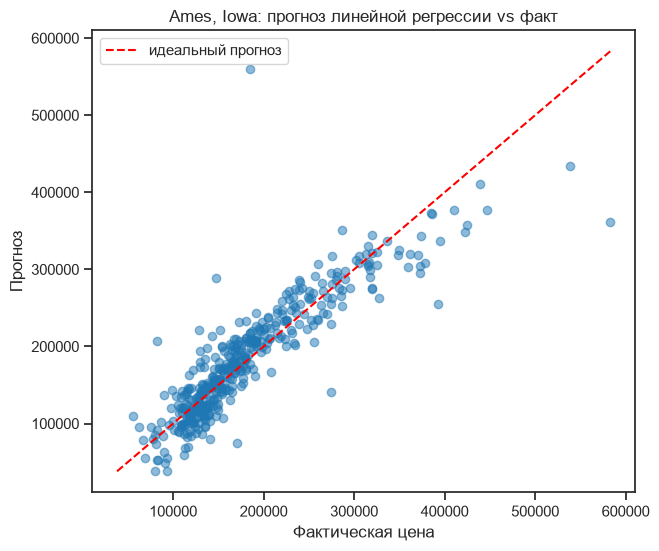

R^2 на тесте = 0.7727


In [9]:
lr = LinearRegression().fit(X_train, y_train)
y_test_pred = lr.predict(X_test)

sns.set_context("notebook"); sns.set_style("ticks")
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, y_test_pred, alpha=0.5)
lims = [min(y_test.min(), y_test_pred.min()), max(y_test.max(), y_test_pred.max())]
ax.plot(lims, lims, "r--", label="идеальный прогноз")
ax.set(xlabel="Фактическая цена", ylabel="Прогноз",
       title="Ames, Iowa: прогноз линейной регрессии vs факт")
ax.legend(); plt.show()
print(f"R^2 на тесте = {r2_score(y_test, y_test_pred):.4f}")

Точки в целом идут вдоль диагонали, R² на тесте 0.77. Хуже всего с дорогими домами: там точки сильнее отходят от линии. Их в выборке мало, и цена от площади и качества растёт не совсем линейно.

## Дополнительно: кросс-валидация и переобучение
В целях лабы ещё есть кросс-валидация и bias/variance, поэтому добавил это отдельно. Одно разбиение train/test зависит от того, какие дома случайно попали в тест, а 5-fold кросс-валидация усредняет ошибку по пяти разбиениям. Кривая обучения показывает, как меняется ошибка на train и на валидации, когда данных становится больше.

In [10]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, (Xa, ya) in {"без кодирования": (X, y), "one-hot": (X_ohc, y_ohc)}.items():
    rmse = np.sqrt(-cross_val_score(LinearRegression(), Xa, ya, cv=kf, scoring="neg_mean_squared_error"))
    print(f"{name:16s}: RMSE по фолдам = {np.round(rmse).astype(int)}, среднее = {rmse.mean():,.0f} ± {rmse.std():,.0f}")

без кодирования : RMSE по фолдам = [38475 33137 35017 47968 29359], среднее = 36,791 ± 6,317


one-hot         : RMSE по фолдам = [39817 63256 35669 53063 26605], среднее = 43,682 ± 12,976


без кодирования : на всех данных RMSE train = 34,007, валидация = 36,792


one-hot         : на всех данных RMSE train = 21,208, валидация = 43,681


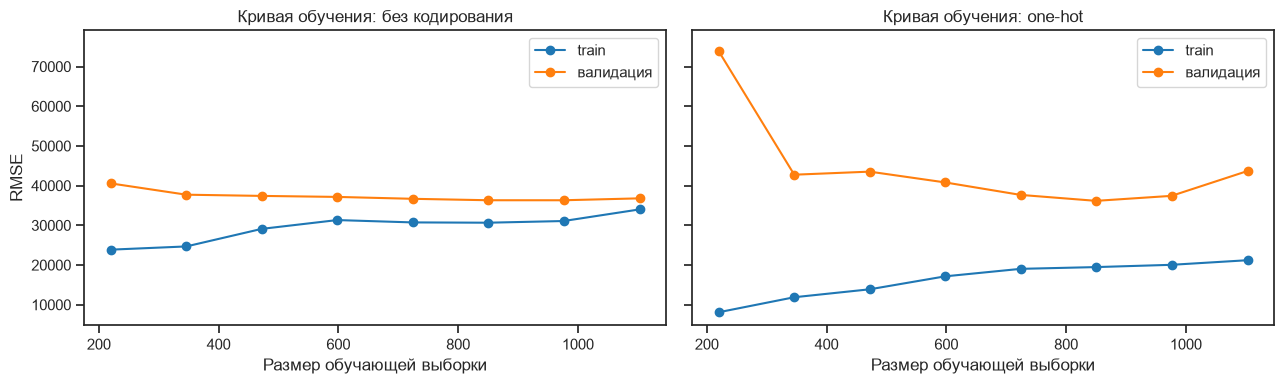

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (name, (Xa, ya)) in zip(axes, {"без кодирования": (X, y), "one-hot": (X_ohc, y_ohc)}.items()):
    sizes, tr_s, val_s = learning_curve(LinearRegression(), Xa, ya, cv=kf,
                                        train_sizes=np.linspace(0.2, 1.0, 8),
                                        scoring="neg_root_mean_squared_error")
    ax.plot(sizes, -tr_s.mean(axis=1), "o-", label="train")
    ax.plot(sizes, -val_s.mean(axis=1), "o-", label="валидация")
    ax.set_title(f"Кривая обучения: {name}"); ax.set_xlabel("Размер обучающей выборки"); ax.legend()
    print(f"{name:16s}: на всех данных RMSE train = {-tr_s.mean(axis=1)[-1]:,.0f}, валидация = {-val_s.mean(axis=1)[-1]:,.0f}")
axes[0].set_ylabel("RMSE"); axes[1].set_ylim(top=np.percentile(-val_s.mean(axis=1), 90) * 1.5)
plt.tight_layout(); plt.show()

Кросс-валидация подтверждает то, что было на одном разбиении. Без кодирования средний RMSE около 36.8 тыс. долларов, и по фолдам он скачет не сильно (± 6.3 тыс.). С one-hot в среднем 43.7 тыс., а разброс в два раза больше (± 13 тыс.), на одном фолде доходит до 63 тыс. У one-hot модели ошибка на train маленькая, а на валидации большая и нестабильная, то есть высокая дисперсия (переобучение). У простой модели train и валидация ближе друг к другу. Для one-hot варианта помогли бы регуляризация (Ridge/Lasso), отбор признаков или просто больше данных.